In [2]:
from matplotlib import pyplot as plt
import numpy as np
import random
np.random.seed(42)

## Chapter 5: Sentiment analysis with the perceptron algorithm

In [3]:
def plot_points(features, labels):
    X = np.array(features)
    y = np.array(labels)
    spam = X[np.argwhere(y==1)]
    ham = X[np.argwhere(y==0)]
    plt.scatter([s[0][0] for s in spam],
                   [s[0][1] for s in spam],
                   s = 100,
                   color = 'cyan',
                   edgecolor = 'k',
                   marker = '^')
    plt.scatter([s[0][0] for s in ham],
                   [s[0][1] for s in ham],
                   s = 100,
                   color = 'red',
                   edgecolor = 'k',
                   marker = 's')
    plt.xlabel('aack')
    plt.ylabel('beep')
    plt.legend(['happy','sad'])
    
def draw_line(a,b,c, starting=0, ending=3, **kwargs):
    # Plotting the line ax + by + c = 0
    x = np.linspace(starting, ending, 1000)
    plt.plot(x, -c/b - a*x/b, **kwargs)
    
def plot_boundary(features, labels, coefficients, intercept):
    # Define the range for the features
    x_min, x_max = features[:, 0].min() - 1, features[:, 0].max() + 1
    y_min, y_max = features[:, 1].min() - 1, features[:, 1].max() + 1

    # Generate x values for the line
    xx = np.linspace(x_min, x_max, 100)

    # Calculate corresponding y values using the equation of the line:
    # w0*x0 + w1*x1 + intercept = 0
    # x1 = (-w0*x0 - intercept) / w1
    yy = (-coefficients[0] * xx - intercept) / coefficients[1]

    # Plot the decision boundary (line)
    plt.plot(xx, yy, color='green', linestyle='-', label='Decision Boundary')

    # Re-plot the original points
    # Separate points based on their labels
    features_label0 = features[labels == 0]
    features_label1 = features[labels == 1]

    # Plot points with label 0 as red squares
    plt.scatter(features_label0[:, 0], features_label0[:, 1], c='red', marker='s', label='Label 0')

    # Plot points with label 1 as blue triangles
    plt.scatter(features_label1[:, 0], features_label1[:, 1], c='blue', marker='^', label='Label 1')

    # Add labels and title
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title('Perceptron Decision Boundary and Data Points')
    plt.legend()
    plt.grid(True)
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.show()

#### Defining and plotting our dataset

In [4]:
features = np.array([[1,0],[0,2],[1,1],[1,2],[1,3],[2,2],[2,3],[3,2]])
labels = np.array([0,0,0,0,1,1,1,1])    # 1 for happy stcs, 0 vv

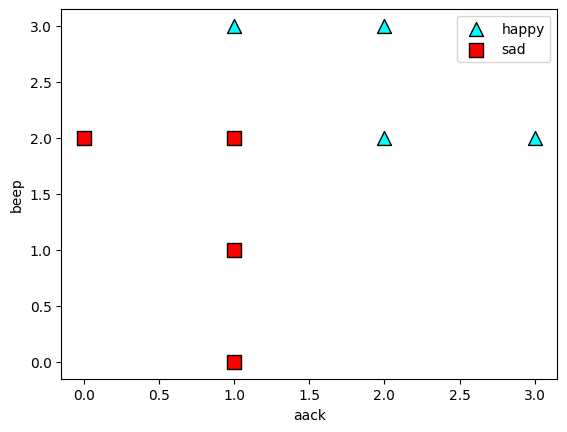

In [5]:
# Plotting the points
plot_points(features, labels)

# Uncomment the following line to see a good line fit for this data.
#draw_line(1,1,-3.5)

#### Coding the perceptron trick

In [6]:
def score(weights, bias, features):
    return features.dot(weights) + bias

# Looks at the score, and if it is (+ve) or zero, returns 1; if it is (-ve), returns 0
def step(x):
    if (x >= 0):
        return 1
    else:
        return 0

# The prediction is the step function of the score.
def prediction(weights, bias, features):
    return step(score(weights, bias, features))

#  If the pdn is equal to the label, then the pt is well cfd, which means the error is zero.
def error(weights, bias, features, label):
    pred = prediction(weights, bias, features)
    if (pred == label):
        return 0
    else:   # if misclassified, then the error is equal to the abs value of the score
        return np.abs(score(weights, bias, features))

def mean_perceptron_error(weights, bias, features, labels):
    total_error = 0
    for i in range(len(features)):
        total_error += error(weights, bias, features[i], labels[i])
    return (total_error / len(features))

In [7]:
weights = [1, 2]
bias = -4

for i in range(len(features)):
    print(prediction(weights, bias, features[i]), error(weights, bias, features[i], labels[i]))

0 0
1 0
0 0
1 1
1 0
1 0
1 0
1 0


In [8]:
def perceptron_trick(weights, bias, features, label, learning_rate = 0.05):
    pred = prediction(weights, bias, features)
    if (pred == label):
        return weights, bias
    else:
        if (label == 1) and (pred == 0):
            for i in range(len(features)):
                weights[i] += features[i] * learning_rate
            bias += learning_rate
        elif (label == 0) and (label == 1):
            for i in range(len(features)):
                weights[i] -= features[i] * learning_rate
            bias -= learning_rate
    return weights, bias

In [9]:
# Shorter version of the perceptron trick
def perceptron_trick(weights, bias, features, label, learning_rate = 0.05):
    pred = prediction(weights, bias, features)
    for i in range(len(weights)):
        weights[i] += (label-pred)*features[i]*learning_rate
        bias += (label-pred)*learning_rate
    return weights, bias

 It uses the 6th example and its true label (0) to adjust the weights and bias, shifting the decision boundary toward a better classification. It repeats this process when run again etc.

In [10]:
perceptron_trick(weights, bias, features[6], 0)

([np.float64(0.9), np.float64(1.85)], -4.1)

#### Running the perceptron algorithm

In [11]:
def perceptron_algorithm(features, labels, learning_rate = 0.01, epochs = 200):
    weights = [1.0 for i in range(len(features[0]))]    # Initializes the weights to 1 and the bias to 0.
    bias = 0.0
    errors = []
    for epoch in range(epochs):
        draw_line(weights[0], weights[1], bias, color='grey', linewidth=1.0, linestyle='dotted')
        error = mean_perceptron_error(weights, bias, features, labels)
        errors.append(error)
        i = random.randint(0, len(features) - 1) # Picks a random point in our dataset.
        weights, bias = perceptron_trick(weights, bias, features[i], labels[i])
    draw_line(weights[0], weights[1], bias)
    plot_points(features, labels)
    plt.show()
    plt.scatter(range(epochs), errors)
    return weights, bias

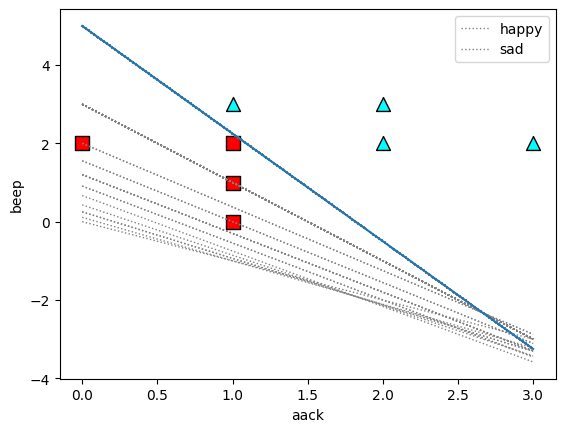

([np.float64(0.5499999999999996), np.float64(0.20000000000000004)],
 np.float64(-1.0000000000000002))

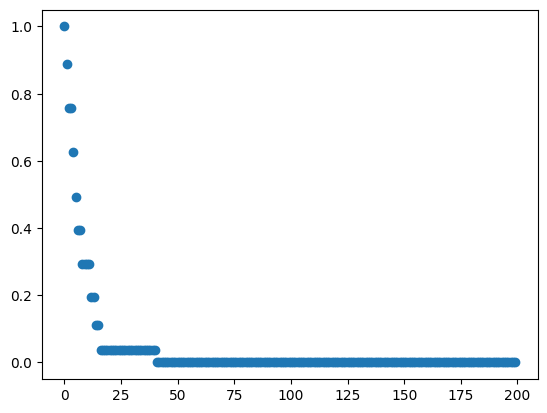

In [12]:
perceptron_algorithm(features, labels)